# Channel Geometry Model

This notebook estimates the designed channel width and height required to obtain an effective measured channel of `1.00 x 1.00 mm` (`1.00 mm2`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from notebook_plot_saver import configure_notebook_plot_saving

PLOT_OUTPUT_ROOT = configure_notebook_plot_saving("notebook_figures")
pd.set_option("display.max_columns", None)
print(f"Notebook figures will be saved under: {PLOT_OUTPUT_ROOT}")

Notebook figures will be saved under: C:\Users\sarklug\Documents\Visual Studio Code\3D_Printing_Project\notebook_figures


## Measurements and assumptions

- Flow-ratio values `118` and `122` are interpreted as `1.18` and `1.22`.
- Layer height is fixed at `0.18 mm`, so its effect cannot be estimated.
- Effective width and height are the averages of the outer and inner measurements.
- The tests use square designed channels. Width and height are calibrated separately so the recommended design may be rectangular.
- The unmeasured `1.00 mm` row is retained as a planned geometry but excluded from fitting.

In [2]:
channel_measurements = pd.DataFrame([
    {"flow_ratio_percent": 122, "layer_height_mm": 0.18, "designed_width_mm": 3.00, "designed_height_mm": 3.00, "outer_width_mm": 2.70, "inner_width_mm": 2.61, "outer_height_mm": 2.74, "inner_height_mm": 2.40, "reported_area_mm2": 6.83, "reported_area_deviation_percent": 24.09, "reported_flow_deviation_percent": 21.23},
    {"flow_ratio_percent": 122, "layer_height_mm": 0.18, "designed_width_mm": 2.50, "designed_height_mm": 2.50, "outer_width_mm": 2.31, "inner_width_mm": 2.07, "outer_height_mm": 2.28, "inner_height_mm": 2.30, "reported_area_mm2": 5.01, "reported_area_deviation_percent": 19.78, "reported_flow_deviation_percent": 21.23},
    {"flow_ratio_percent": 122, "layer_height_mm": 0.18, "designed_width_mm": 2.00, "designed_height_mm": 2.00, "outer_width_mm": 1.74, "inner_width_mm": 1.54, "outer_height_mm": 1.97, "inner_height_mm": 1.93, "reported_area_mm2": 3.21, "reported_area_deviation_percent": 19.83, "reported_flow_deviation_percent": 21.23},
    {"flow_ratio_percent": 118, "layer_height_mm": 0.18, "designed_width_mm": 2.00, "designed_height_mm": 2.00, "outer_width_mm": 1.94, "inner_width_mm": 1.79, "outer_height_mm": 2.01, "inner_height_mm": 1.69, "reported_area_mm2": 3.45, "reported_area_deviation_percent": 13.75, "reported_flow_deviation_percent": 29.87},
    {"flow_ratio_percent": 118, "layer_height_mm": 0.18, "designed_width_mm": 1.50, "designed_height_mm": 1.50, "outer_width_mm": 1.10, "inner_width_mm": 1.31, "outer_height_mm": 1.00, "inner_height_mm": 1.01, "reported_area_mm2": 1.22, "reported_area_deviation_percent": 45.99, "reported_flow_deviation_percent": 29.87},
    {"flow_ratio_percent": 118, "layer_height_mm": 0.18, "designed_width_mm": 1.00, "designed_height_mm": 1.00, "outer_width_mm": np.nan, "inner_width_mm": np.nan, "outer_height_mm": np.nan, "inner_height_mm": np.nan, "reported_area_mm2": np.nan, "reported_area_deviation_percent": np.nan, "reported_flow_deviation_percent": 29.87},
])

channel_measurements["flow_ratio"] = channel_measurements["flow_ratio_percent"] / 100
channel_measurements["effective_width_mm"] = channel_measurements[["outer_width_mm", "inner_width_mm"]].mean(axis=1)
channel_measurements["effective_height_mm"] = channel_measurements[["outer_height_mm", "inner_height_mm"]].mean(axis=1)
channel_measurements["calculated_area_mm2"] = channel_measurements["effective_width_mm"] * channel_measurements["effective_height_mm"]
channel_measurements["calculated_area_deviation_percent"] = 100 * (channel_measurements["designed_width_mm"] * channel_measurements["designed_height_mm"] - channel_measurements["calculated_area_mm2"]) / (channel_measurements["designed_width_mm"] * channel_measurements["designed_height_mm"])

display(channel_measurements.round(3))

,flow_ratio_percent,layer_height_mm,designed_width_mm,designed_height_mm,outer_width_mm,inner_width_mm,outer_height_mm,inner_height_mm,reported_area_mm2,reported_area_deviation_percent,reported_flow_deviation_percent,flow_ratio,effective_width_mm,effective_height_mm,calculated_area_mm2,calculated_area_deviation_percent
0,122,0.18,3.0,3.0,2.70,2.61,2.74,2.40,6.83,24.09,21.23,1.22,2.655,2.570,6.823,24.185
1,122,0.18,2.5,2.5,2.31,2.07,2.28,2.30,5.01,19.78,21.23,1.22,2.190,2.290,5.015,19.758
2,122,0.18,2.0,2.0,1.74,1.54,1.97,1.93,3.21,19.83,21.23,1.22,1.640,1.950,3.198,20.050
3,118,0.18,2.0,2.0,1.94,1.79,2.01,1.69,3.45,13.75,29.87,1.18,1.865,1.850,3.450,13.744
4,118,0.18,1.5,1.5,1.10,1.31,1.00,1.01,1.22,45.99,29.87,1.18,1.205,1.005,1.211,46.177
5,118,0.18,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,29.87,1.18,NaN,NaN,NaN,NaN


## Local inverse model

The `1.18` flow-ratio series contains the closest measured channel to the target. A local linear calibration is fitted separately for width and height using its `1.50 mm` and `2.00 mm` designs. This is a geometric calibration with no residual degrees of freedom, so a confirmation print is required.

In [3]:
TARGET_FLOW_RATIO = 1.18
TARGET_WIDTH_MM = 1.00
TARGET_HEIGHT_MM = 1.00
DESIGN_INCREMENT_MM = 0.05

model_data = channel_measurements.dropna(subset=["effective_width_mm", "effective_height_mm"]).copy()
local_data = model_data[model_data["flow_ratio"].eq(TARGET_FLOW_RATIO)].sort_values("designed_width_mm")
if len(local_data) < 2:
    raise ValueError("At least two measured channels are required at the selected flow ratio.")

width_slope, width_intercept = np.polyfit(local_data["designed_width_mm"], local_data["effective_width_mm"], 1)
height_slope, height_intercept = np.polyfit(local_data["designed_height_mm"], local_data["effective_height_mm"], 1)

required_width_mm = (TARGET_WIDTH_MM - width_intercept) / width_slope
required_height_mm = (TARGET_HEIGHT_MM - height_intercept) / height_slope
rounded_width_mm = round(required_width_mm / DESIGN_INCREMENT_MM) * DESIGN_INCREMENT_MM
rounded_height_mm = round(required_height_mm / DESIGN_INCREMENT_MM) * DESIGN_INCREMENT_MM

def predict_effective_width(designed_width_mm):
    return width_intercept + width_slope * np.asarray(designed_width_mm)

def predict_effective_height(designed_height_mm):
    return height_intercept + height_slope * np.asarray(designed_height_mm)

def prediction_row(label, designed_width_mm, designed_height_mm):
    predicted_width = float(predict_effective_width(designed_width_mm))
    predicted_height = float(predict_effective_height(designed_height_mm))
    return {
        "design": label,
        "flow_ratio": TARGET_FLOW_RATIO,
        "layer_height_mm": 0.18,
        "designed_width_mm": designed_width_mm,
        "designed_height_mm": designed_height_mm,
        "predicted_width_mm": predicted_width,
        "predicted_height_mm": predicted_height,
        "predicted_area_mm2": predicted_width * predicted_height,
    }

channel_recommendations = pd.DataFrame([
    prediction_row("Exact inverse-model solution", required_width_mm, required_height_mm),
    prediction_row(f"Rounded to {DESIGN_INCREMENT_MM:.2f} mm", rounded_width_mm, rounded_height_mm),
])

channel_model_coefficients = pd.DataFrame([
    {"response": "Effective width (mm)", "intercept": width_intercept, "slope": width_slope},
    {"response": "Effective height (mm)", "intercept": height_intercept, "slope": height_slope},
])

print(f"Width model: measured width = {width_intercept:.3f} + {width_slope:.3f} x designed width")
print(f"Height model: measured height = {height_intercept:.3f} + {height_slope:.3f} x designed height")
print(f"Recommended confirmation geometry: {rounded_width_mm:.2f} x {rounded_height_mm:.2f} mm at flow ratio {TARGET_FLOW_RATIO:.2f}")
display(channel_model_coefficients.round(4))
display(channel_recommendations.round(4))

Width model: measured width = -0.775 + 1.320 x designed width
Height model: measured height = -1.530 + 1.690 x designed height
Recommended confirmation geometry: 1.35 x 1.50 mm at flow ratio 1.18


,response,intercept,slope
0,Effective width (mm),-0.775,1.32
1,Effective height (mm),-1.530,1.69


,design,flow_ratio,layer_height_mm,designed_width_mm,designed_height_mm,predicted_width_mm,predicted_height_mm,predicted_area_mm2
0,Exact inverse-model solution,1.18,0.18,1.3447,1.497,1.000,1.000,1.000
1,Rounded to 0.05 mm,1.18,0.18,1.3500,1.500,1.007,1.005,1.012


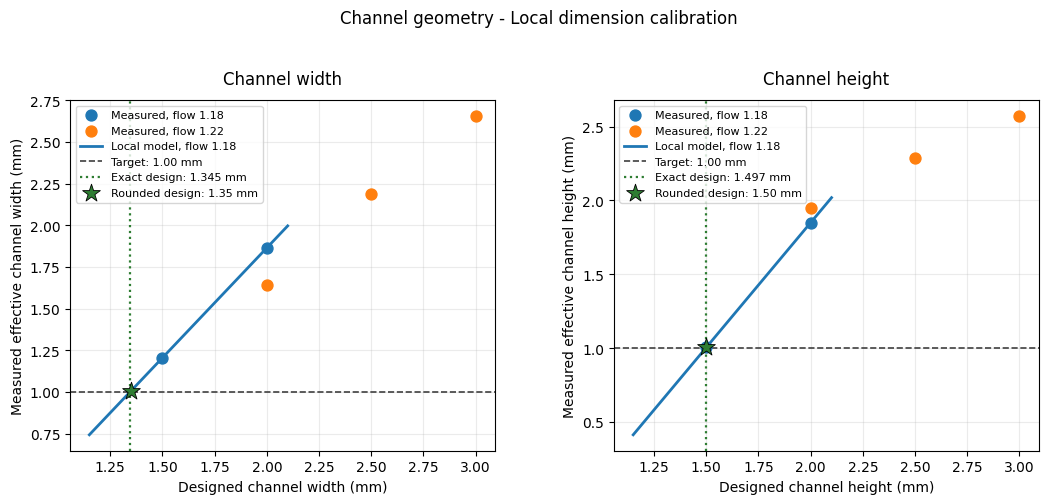

In [4]:
flow_colors = {1.18: "#1f77b4", 1.22: "#ff7f0e"}
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))
plot_specs = [
    (axes[0], "designed_width_mm", "effective_width_mm", predict_effective_width, required_width_mm, rounded_width_mm, "Channel width"),
    (axes[1], "designed_height_mm", "effective_height_mm", predict_effective_height, required_height_mm, rounded_height_mm, "Channel height"),
]

for ax, x_column, y_column, predictor, exact_design, rounded_design, dimension_label in plot_specs:
    for flow_ratio, group in model_data.groupby("flow_ratio"):
        ax.scatter(group[x_column], group[y_column], s=62, color=flow_colors[flow_ratio], label=f"Measured, flow {flow_ratio:.2f}", zorder=3)
    x_line = np.linspace(1.15, 2.10, 200)
    ax.plot(x_line, predictor(x_line), color=flow_colors[TARGET_FLOW_RATIO], linewidth=2, label="Local model, flow 1.18")
    ax.axhline(1.00, color="0.25", linestyle="--", linewidth=1.2, label="Target: 1.00 mm")
    ax.axvline(exact_design, color="#2e7d32", linestyle=":", linewidth=1.6, label=f"Exact design: {exact_design:.3f} mm")
    ax.scatter([rounded_design], [float(predictor(rounded_design))], marker="*", s=180, color="#2e7d32", edgecolor="black", linewidth=0.6, label=f"Rounded design: {rounded_design:.2f} mm", zorder=4)
    ax.set_title(dimension_label, pad=12)
    ax.set_xlabel(f"Designed {dimension_label.lower()} (mm)")
    ax.set_ylabel(f"Measured effective {dimension_label.lower()} (mm)")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8, loc="upper left")

fig.suptitle("Channel geometry - Local dimension calibration", y=1.03)
fig.subplots_adjust(top=0.84, wspace=0.28)
plt.show()

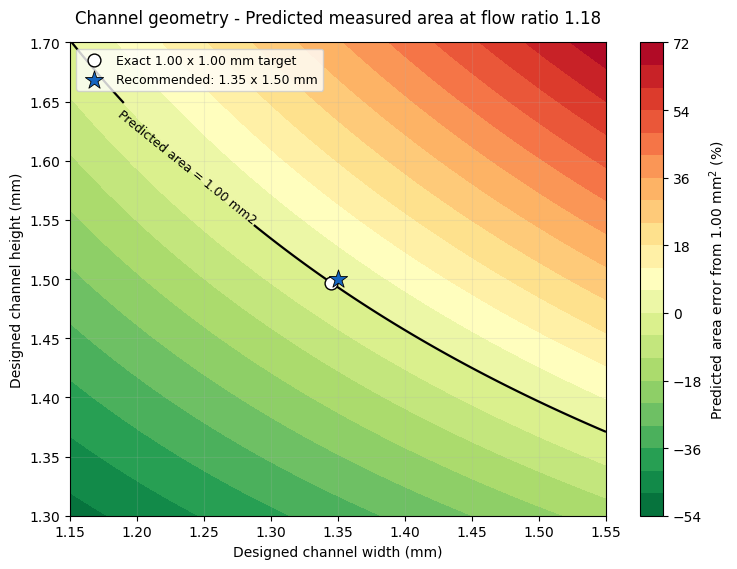

In [5]:
width_grid = np.linspace(1.15, 1.55, 180)
height_grid = np.linspace(1.30, 1.70, 180)
designed_width_grid, designed_height_grid = np.meshgrid(width_grid, height_grid)
predicted_width_grid = predict_effective_width(designed_width_grid)
predicted_height_grid = predict_effective_height(designed_height_grid)
predicted_area_grid = predicted_width_grid * predicted_height_grid
area_error_percent = 100 * (predicted_area_grid - 1.00)

fig, ax = plt.subplots(figsize=(7.6, 5.8))
filled = ax.contourf(designed_width_grid, designed_height_grid, area_error_percent, levels=21, cmap="RdYlGn_r")
area_contour = ax.contour(designed_width_grid, designed_height_grid, predicted_area_grid, levels=[1.00], colors="black", linewidths=1.6)
ax.clabel(area_contour, fmt={1.00: "Predicted area = 1.00 mm2"}, fontsize=9)
ax.scatter(required_width_mm, required_height_mm, marker="o", s=85, color="white", edgecolor="black", label="Exact 1.00 x 1.00 mm target", zorder=4)
ax.scatter(rounded_width_mm, rounded_height_mm, marker="*", s=190, color="#1565c0", edgecolor="black", linewidth=0.6, label=f"Recommended: {rounded_width_mm:.2f} x {rounded_height_mm:.2f} mm", zorder=5)
colorbar = fig.colorbar(filled, ax=ax)
colorbar.set_label("Predicted area error from 1.00 mm$^2$ (%)")
ax.set_title("Channel geometry - Predicted measured area at flow ratio 1.18", pad=14)
ax.set_xlabel("Designed channel width (mm)")
ax.set_ylabel("Designed channel height (mm)")
ax.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.18)
plt.tight_layout()
plt.show()

## Recommendation

Use a designed channel of approximately **1.35 mm width x 1.50 mm height**, with **flow ratio 1.18** and **layer height 0.18 mm**, as the next confirmation print. The local model predicts approximately `1.007 x 1.005 mm`, or `1.012 mm2`, after rounding to `0.05 mm`.

The width recommendation is a small extrapolation below the smallest measured design (`1.50 mm`). Treat this as a confirmation candidate, then add its measured outer and inner dimensions to the table and refit before selecting a final production geometry.